# Adaptive smooth

Standard smooths use a single smoothing parameter, so the same amount of smoothness is
applied across the whole range of the covariate. When a function is very wiggly in some
regions and smooth in others, this forces a compromise: the fit is either too smooth
where the function changes quickly, or too wiggly where it changes slowly.

The [`AdaptiveSmooth`][pymgcv.basis_functions.AdaptiveSmooth] basis lets the strength
of the penalty vary with the covariate, by using several smoothing parameters. In this
example, we simulate data from a function that oscillates quickly for small `x` and
slowly for large `x`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pymgcv.basis_functions import AdaptiveSmooth
from pymgcv.gam import GAM
from pymgcv.terms import S

rng = np.random.default_rng(1)
n = 300
x = np.sort(rng.uniform(0, 1, n))
f_true = np.sin(4 / (x + 0.15))
data = pd.DataFrame({"x": x, "y": f_true + rng.normal(scale=0.2, size=n)})

We fit a standard smooth (a thin plate regression spline) and an adaptive smooth,
using the same basis dimension `k=40` for both, and compare the fits against the true
function.

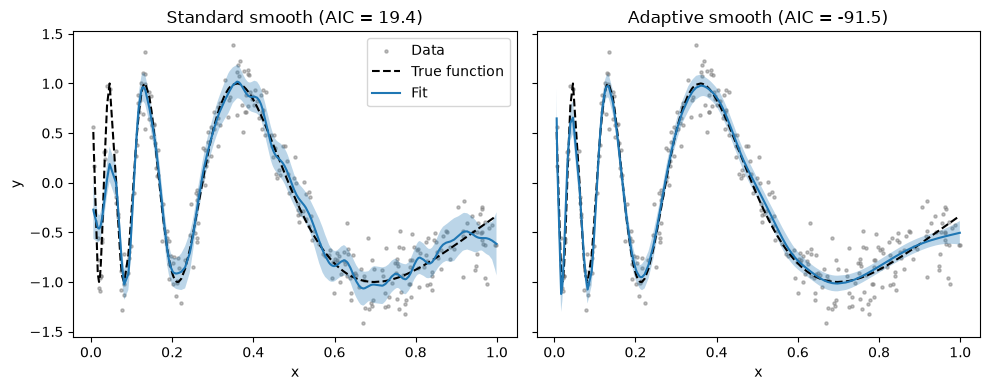

In [2]:
models = {
    "Standard smooth": GAM({"y": S("x", k=40)}),
    "Adaptive smooth": GAM({"y": S("x", k=40, bs=AdaptiveSmooth())}),
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, gam) in zip(axes, models.items(), strict=True):
    gam.fit(data)
    pred = gam.predict(data, compute_se=True)["y"]
    ax.scatter(x, data["y"], s=5, color="grey", alpha=0.5, label="Data")
    ax.plot(x, f_true, color="black", linestyle="--", label="True function")
    ax.plot(x, pred.fit, label="Fit")
    ax.fill_between(x, pred.fit - 2 * pred.se, pred.fit + 2 * pred.se, alpha=0.3)
    ax.set_title(f"{name} (AIC = {gam.aic():.1f})")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend()
fig.tight_layout()
plt.show()

The standard smooth misses the fast oscillations for small `x`, while being
needlessly wiggly for large `x`. The adaptive smooth follows the fast oscillations and
is smooth where the function changes slowly, and it has a much lower AIC.

The number of smoothing parameters can be set with `penalty_basis_dim` (default 5 in
1D), and the smoothing basis with `bs` (a
[`PSpline`][pymgcv.basis_functions.PSpline] by default).

!!! warning

    Adaptive smooths should be used sparingly: each extra smoothing parameter has to be
    estimated from the data, which requires a lot of data. It is often as effective to
    transform the covariate.

## Two variables

Adaptive smooths can also be used for smooths of two variables. Here we simulate data
from a function with a sharp peak near $(0.25, 0.25)$ and a gentle slope elsewhere, and
again compare a standard smooth (with `k=100`) to an adaptive smooth (with the default
basis dimensions).

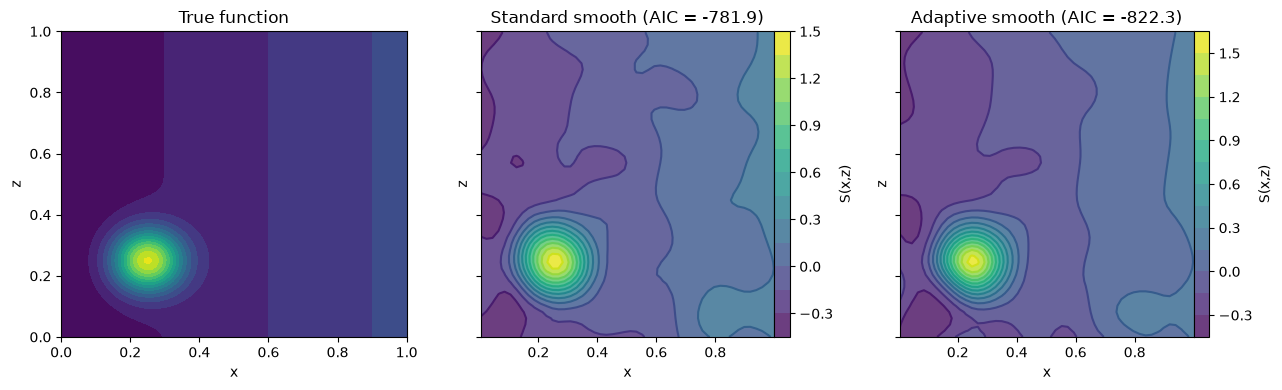

In [3]:
import pymgcv.plot as gplt

n = 500
x = rng.uniform(0, 1, n)
z = rng.uniform(0, 1, n)


def f(x, z):
    return 2 * np.exp(-((x - 0.25) ** 2 + (z - 0.25) ** 2) / 0.01) + 0.5 * x


data2d = pd.DataFrame({"x": x, "z": z, "y": f(x, z) + rng.normal(scale=0.1, size=n)})

models2d = {
    "Standard smooth": GAM({"y": S("x", "z", k=100)}),
    "Adaptive smooth": GAM({"y": S("x", "z", bs=AdaptiveSmooth())}),
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
xx, zz = np.meshgrid(np.linspace(0, 1, 100), np.linspace(0, 1, 100))
axes[0].contourf(xx, zz, f(xx, zz), levels=20)
axes[0].set_title("True function")
axes[0].set_xlabel("x")
axes[0].set_ylabel("z")
for ax, (name, gam) in zip(axes[1:], models2d.items(), strict=True):
    gam.fit(data2d)
    gplt.continuous_2d(term=0, gam=gam, data=data2d, ax=ax, scatter_kwargs={"disable": True})
    ax.set_title(f"{name} (AIC = {gam.aic():.1f})")
fig.tight_layout()
plt.show()

Both smooths capture the peak, but the adaptive smooth has a lower AIC, as it can use
less smoothing near the peak than elsewhere. The difference is smaller than in the
one-dimensional example, as by default the penalty only varies over a coarse
$3 \times 3$ basis. Note that the fitted smooths are centered, so their colour scales
differ from that of the true function.

For two variables, `penalty_basis_dim` can also be a pair, setting the penalty basis
dimension for each variable separately (default 3 for each).